<a href="https://colab.research.google.com/github/caohuongquynh/PlantVillage/blob/main/plantvillageCNN_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from PIL import Image
from collections import defaultdict
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import pickle
import shutil
import json
import random
import warnings
warnings.filterwarnings('ignore')


DATASET_PATH = '/content/drive/MyDrive/Plantvillage dataset'
VALID_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff'}
IMG_SIZE    = 128
IMG_SIZE_CNN = IMG_SIZE  # alias for training cells
random.seed(42)

print(' Setup hoàn tất.')
print(f' Dataset path: {DATASET_PATH}')

 Setup hoàn tất.
 Dataset path: /content/drive/MyDrive/Plantvillage dataset


In [ ]:
class_names = sorted(os.listdir(DATASET_PATH))
class_names = [c for c in class_names if os.path.isdir(os.path.join(DATASET_PATH, c)) and c.lower() != 'metadata']

print(f' Tổng số class (38 lớp bệnh): {len(class_names)}')
print(f'\n Danh sách các class:')
for i, c in enumerate(class_names):
    print(f'  [{i:02d}] {c}')

records = []
all_image_paths = []

for cls in class_names:
    cls_dir = os.path.join(DATASET_PATH, cls)
    imgs = [f for f in os.listdir(cls_dir) if os.path.splitext(f)[1].lower() in VALID_EXTS]
    count = len(imgs)

    if count > 0:
        plant_name = cls.split('___')[0]
        disease_name = cls.split('___')[1] if '___' in cls else 'Unknown'
        records.append({
            'class_folder': cls,
            'plant': plant_name,
            'disease': disease_name,
            'count': count
        })
        for img in imgs:
            all_image_paths.append(os.path.join(cls_dir, img))

df_stats = pd.DataFrame(records)
total_images = df_stats['count'].sum()

print(f'\n TỔNG QUAN DATASET')
print(f'  Tổng số ảnh       : {total_images:,}')
print(f'  Tổng số class     : {len(df_stats)}')
print(f'  Số loại cây       : {df_stats["plant"].nunique()}')
print(f'  Ảnh trung bình/class: {df_stats["count"].mean():.0f}')
print(f'  Class ít nhất     : {df_stats["count"].min()} ảnh ({df_stats.loc[df_stats["count"].idxmin(), "class_folder"]})')
print(f'  Class nhiều nhất  : {df_stats["count"].max()} ảnh ({df_stats.loc[df_stats["count"].idxmax(), "class_folder"]})')

 Tổng số class (38 lớp bệnh): 38

 Danh sách các class:
  [00] Apple___Apple_scab
  [01] Apple___Black_rot
  [02] Apple___Cedar_apple_rust
  [03] Apple___healthy
  [04] Blueberry___healthy
  [05] Cherry_(including_sour)___Powdery_mildew
  [06] Cherry_(including_sour)___healthy
  [07] Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  [08] Corn_(maize)___Common_rust_
  [09] Corn_(maize)___Northern_Leaf_Blight
  [10] Corn_(maize)___healthy
  [11] Grape___Black_rot
  [12] Grape___Esca_(Black_Measles)
  [13] Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
  [14] Grape___healthy
  [15] Orange___Haunglongbing_(Citrus_greening)
  [16] Peach___Bacterial_spot
  [17] Peach___healthy
  [18] Pepper,_bell___Bacterial_spot
  [19] Pepper,_bell___healthy
  [20] Potato___Early_blight
  [21] Potato___Late_blight
  [22] Potato___healthy
  [23] Raspberry___healthy
  [24] Soybean___healthy
  [25] Squash___Powdery_mildew
  [26] Strawberry___Leaf_scorch
  [27] Strawberry___healthy
  [28] Tomato___Bacterial_spot

5.1 – CÁC BỆNH XUẤT HIỆN TRÊN NHIỀU LOÀI CÂY

[Bacterial_spot]
 -> Peach, Pepper,_bell, Tomato


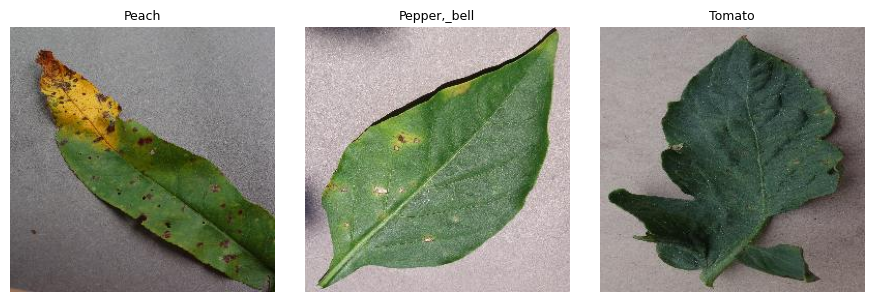


[Black_rot]
 -> Apple, Grape


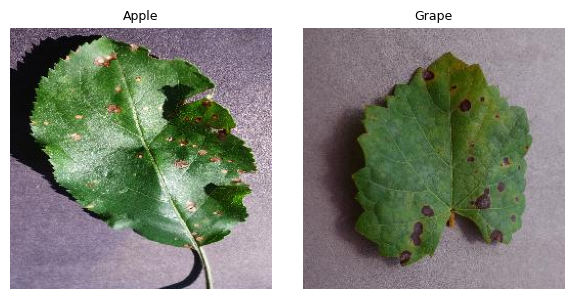


[Early_blight]
 -> Potato, Tomato


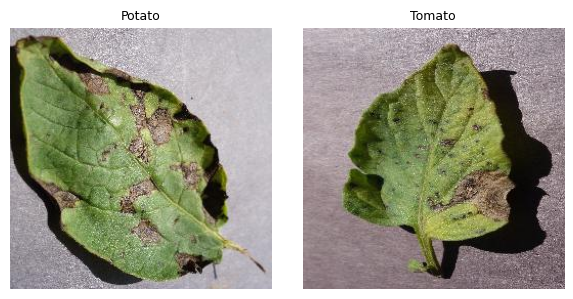


[Late_blight]
 -> Potato, Tomato


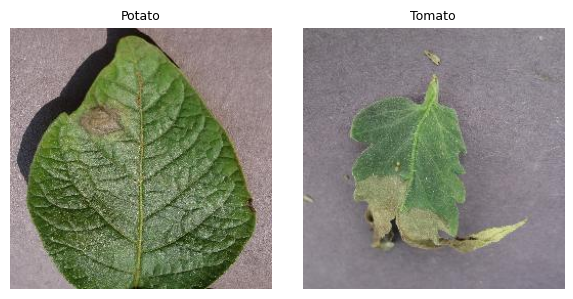


[Powdery_mildew]
 -> Cherry_(including_sour), Squash


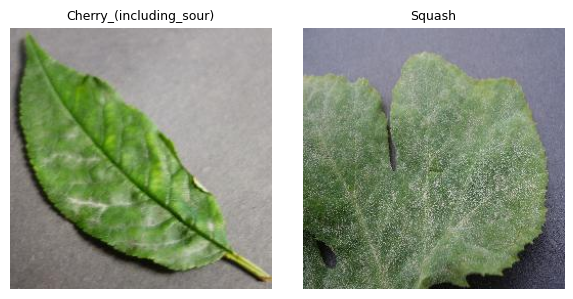


[healthy]
 -> Apple, Blueberry, Cherry_(including_sour), Corn_(maize), Grape, Peach, Pepper,_bell, Potato, Raspberry, Soybean, Strawberry, Tomato


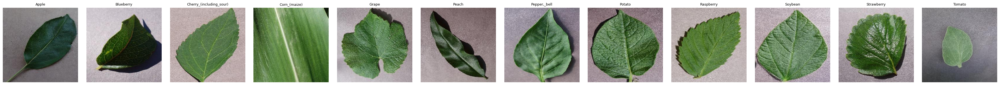

5.2 – CÁC BỆNH ĐẶC THÙ

Apple
 -> Apple_scab, Cedar_apple_rust


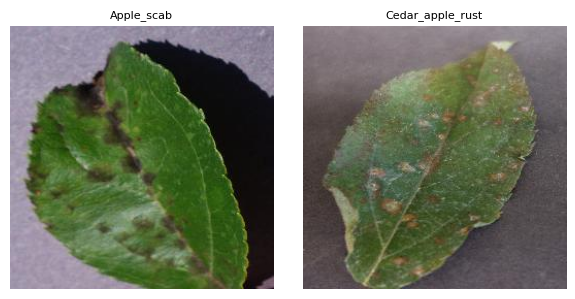


Corn_(maize)
 -> Cercospora_leaf_spot Gray_leaf_spot, Common_rust_, Northern_Leaf_Blight


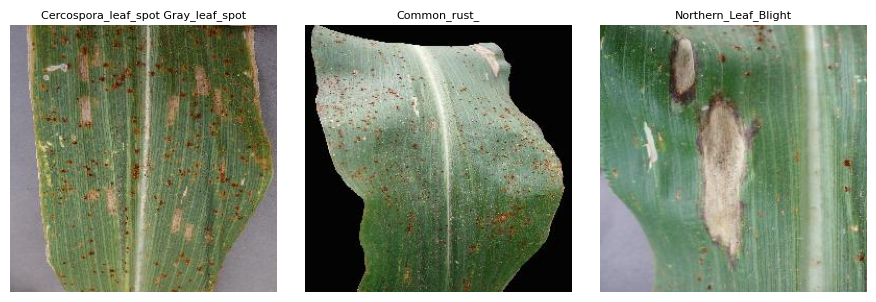


Grape
 -> Esca_(Black_Measles), Leaf_blight_(Isariopsis_Leaf_Spot)


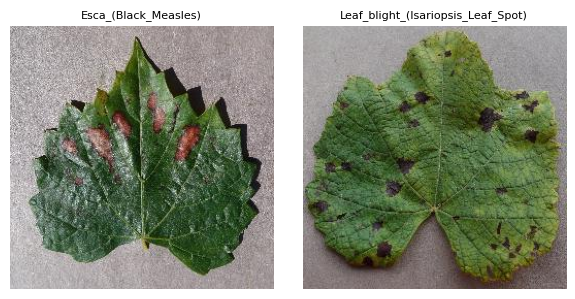


Orange
 -> Haunglongbing_(Citrus_greening)


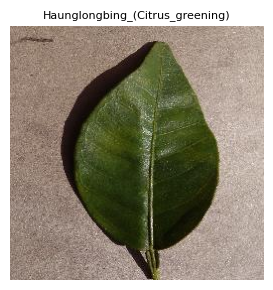


Strawberry
 -> Leaf_scorch


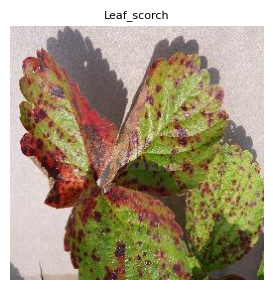


Tomato
 -> Leaf_Mold, Septoria_leaf_spot, Spider_mites Two-spotted_spider_mite, Target_Spot, Tomato_Yellow_Leaf_Curl_Virus, Tomato_mosaic_virus


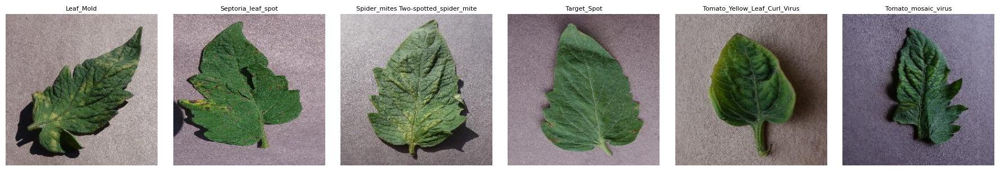

In [ ]:
# ============================================================
# PHÂN TÍCH DỮ LIỆU TỰ ĐỘNG (EDA)
# ============================================================

# --- Chuẩn bị: xây dựng bảng ánh xạ bệnh -> cây ---
disease_to_plants = {}

for _, row in df_stats.iterrows():
    disease_to_plants.setdefault(row["disease"], []).append(row["plant"])


# ============================================================
# 5.1 – CÁC BỆNH XUẤT HIỆN TRÊN NHIỀU LOÀI CÂY
# ============================================================

print("=" * 70)
print("5.1 – CÁC BỆNH XUẤT HIỆN TRÊN NHIỀU LOÀI CÂY")
print("=" * 70)

shared_diseases = {
    disease: sorted(plants)
    for disease, plants in disease_to_plants.items()
    if len(plants) > 1
}

if shared_diseases:

    for disease, plants in sorted(shared_diseases.items()):

        print(f"\n[{disease}]")
        print(" -> " + ", ".join(plants))

        fig, axes = plt.subplots(
            1,
            len(plants),
            figsize=(3 * len(plants), 3)
        )

        if len(plants) == 1:
            axes = [axes]

        for ax, plant in zip(axes, plants):

            folder = os.path.join(DATASET_PATH, f"{plant}___{disease}")

            if os.path.isdir(folder):

                imgs = [
                    f for f in os.listdir(folder)
                    if os.path.splitext(f)[1].lower() in VALID_EXTS
                ]

                if imgs:
                    img = Image.open(
                        os.path.join(folder, imgs[0])
                    ).convert("RGB")

                    ax.imshow(img)

            ax.set_title(plant, fontsize=9)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

else:
    print("Không phát hiện bệnh xuất hiện trên nhiều loài cây.")


# ============================================================
# 5.2 – CÁC BỆNH ĐẶC THÙ
# ============================================================

print("=" * 70)
print("5.2 – CÁC BỆNH ĐẶC THÙ")
print("=" * 70)

plant_to_unique_diseases = {}

for disease, plants in disease_to_plants.items():

    if len(plants) == 1 and disease.lower() != "healthy":

        plant = plants[0]

        plant_to_unique_diseases.setdefault(
            plant,
            []
        ).append(disease)

if plant_to_unique_diseases:

    for plant, diseases in sorted(plant_to_unique_diseases.items()):

        print(f"\n{plant}")
        print(" -> " + ", ".join(diseases))

        fig, axes = plt.subplots(
            1,
            len(diseases),
            figsize=(3 * len(diseases), 3)
        )

        if len(diseases) == 1:
            axes = [axes]

        for ax, disease in zip(axes, diseases):

            folder = os.path.join(
                DATASET_PATH,
                f"{plant}___{disease}"
            )

            if os.path.isdir(folder):

                imgs = [
                    f for f in os.listdir(folder)
                    if os.path.splitext(f)[1].lower() in VALID_EXTS
                ]

                if imgs:

                    img = Image.open(
                        os.path.join(folder, imgs[0])
                    ).convert("RGB")

                    ax.imshow(img)

            ax.set_title(disease, fontsize=8)
            ax.axis("off")

        plt.tight_layout()
        plt.show()

else:
    print("Không phát hiện bệnh đặc thù.")

In [ ]:
max_count = df_stats['count'].max()
min_count = df_stats['count'].min()
imbalance_ratio = max_count / min_count

mean_count = df_stats['count'].mean()
std_count = df_stats['count'].std()
cv = (std_count / mean_count) * 100

print('⚖️ PHÂN TÍCH MẤT CÂN BẰNG DỮ LIỆU')
print(f'  Tỉ lệ class nhiều nhất / ít nhất: {imbalance_ratio:.2f}x')
print(f'  Trung bình ảnh/class             : {mean_count:.0f}')
print(f'  Độ lệch chuẩn                   : {std_count:.0f}')
print(f'  Coefficient of Variation (CV)   : {cv:.1f}%')
print()
if cv < 20:
    print('   Dữ liệu CÂN BẰNG TỐT (CV < 20%)')
elif cv < 40:
    print('   Dữ liệu MẤT CÂN BẰNG NHẸ (20% ≤ CV < 40%)')
else:
    print('   Dữ liệu MẤT CÂN BẰNG NẶNG (CV ≥ 40%) → Cần xử lý!')

⚖️ PHÂN TÍCH MẤT CÂN BẰNG DỮ LIỆU
  Tỉ lệ class nhiều nhất / ít nhất: 14.37x
  Trung bình ảnh/class             : 597
  Độ lệch chuẩn                   : 296
  Coefficient of Variation (CV)   : 49.6%

   Dữ liệu MẤT CÂN BẰNG NẶNG (CV ≥ 40%) → Cần xử lý!


In [ ]:
# ============================================================
# TÍNH CLASS WEIGHT – Xử lý mất cân bằng dữ liệu
# ============================================================
print('⚖️ TÍNH CLASS WEIGHT CHO TOÀN BỘ DATASET')

cw_disease = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(df_stats.index),
    y=np.repeat(df_stats.index, df_stats['count'])
)
class_weight_disease = dict(enumerate(cw_disease))

plant_counts = df_stats.groupby('plant')['count'].sum()
cw_plant = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(plant_counts)),
    y=np.repeat(np.arange(len(plant_counts)), plant_counts.values)
)
class_weight_plant = dict(enumerate(cw_plant))

with open('/content/class_weight_disease.json', 'w') as f:
    json.dump({str(k): float(v) for k, v in class_weight_disease.items()}, f, indent=2)
with open('/content/class_weight_plant.json', 'w') as f:
    json.dump({str(k): float(v) for k, v in class_weight_plant.items()}, f, indent=2)

print(' Đã tính và xuất siêu tham số class_weight ra file JSON.')

⚖️ TÍNH CLASS WEIGHT CHO TOÀN BỘ DATASET
 Đã tính và xuất siêu tham số class_weight ra file JSON.


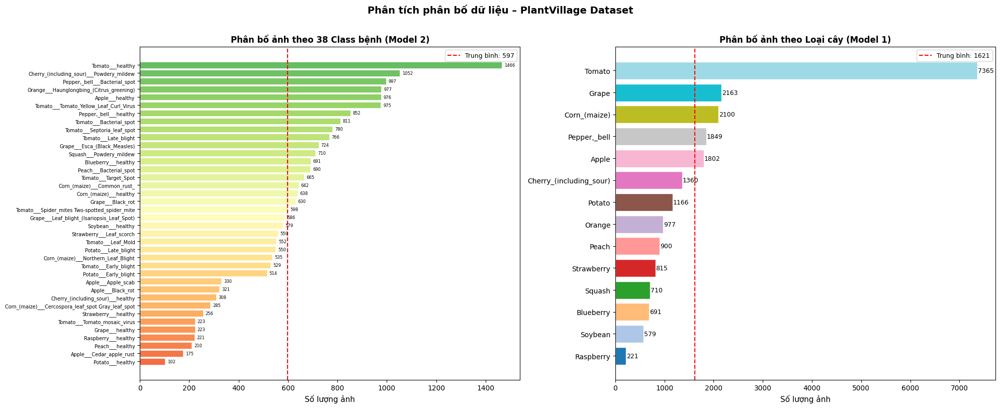

In [ ]:
df_sorted = df_stats.sort_values('count', ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

colors = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(df_sorted)))
bars = axes[0].barh(range(len(df_sorted)), df_sorted['count'], color=colors, edgecolor='white', linewidth=0.5)
axes[0].set_yticks(range(len(df_sorted)))
axes[0].set_yticklabels(df_sorted['class_folder'], fontsize=7)
axes[0].set_xlabel('Số lượng ảnh', fontsize=11)
axes[0].set_title('Phân bố ảnh theo 38 Class bệnh (Model 2)', fontsize=12, fontweight='bold')
axes[0].axvline(x=df_sorted['count'].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Trung bình: {df_sorted["count"].mean():.0f}')
axes[0].legend(fontsize=9)
for bar, val in zip(bars, df_sorted['count']):
    axes[0].text(val + 10, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=6)

plant_stats = df_stats.groupby('plant')['count'].sum().sort_values(ascending=True)
colors2 = plt.cm.tab20(np.linspace(0, 1, len(plant_stats)))
bars2 = axes[1].barh(range(len(plant_stats)), plant_stats.values, color=colors2, edgecolor='white')
axes[1].set_yticks(range(len(plant_stats)))
axes[1].set_yticklabels(plant_stats.index, fontsize=10)
axes[1].set_xlabel('Số lượng ảnh', fontsize=11)
axes[1].set_title('Phân bố ảnh theo Loại cây (Model 1)', fontsize=12, fontweight='bold')
axes[1].axvline(x=plant_stats.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Trung bình: {plant_stats.mean():.0f}')
axes[1].legend(fontsize=9)
for bar, val in zip(bars2, plant_stats.values):
    axes[1].text(val + 10, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)

plt.suptitle('Phân tích phân bố dữ liệu – PlantVillage Dataset', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

📐 PHÂN TÍCH KÍCH THƯỚC ẢNH (mẫu 500 ảnh)
  Chiều rộng (W): min=256, max=256, mean=256
  Chiều cao  (H): min=256, max=256, mean=256
  Kích thước phổ biến nhất: (256, 256)
  Số kênh màu: {3}


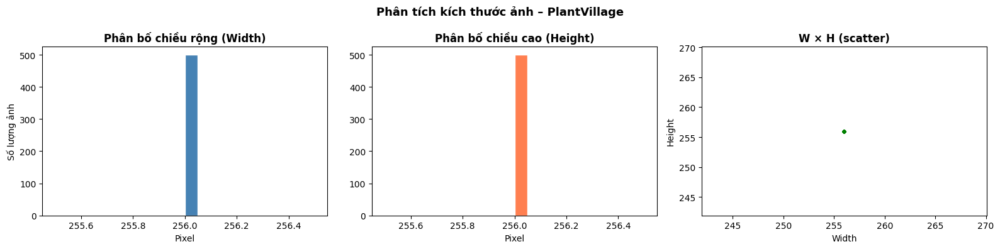

In [ ]:
sample_paths = random.sample(all_image_paths, min(500, len(all_image_paths)))
widths, heights, channels = [], [], []
errors = []

for path in sample_paths:
    try:
        img = Image.open(path)
        w, h = img.size
        ch = len(img.getbands())
        widths.append(w)
        heights.append(h)
        channels.append(ch)
    except Exception as e:
        errors.append(path)

print('📐 PHÂN TÍCH KÍCH THƯỚC ẢNH (mẫu 500 ảnh)')
print(f'  Chiều rộng (W): min={min(widths)}, max={max(widths)}, mean={np.mean(widths):.0f}')
print(f'  Chiều cao  (H): min={min(heights)}, max={max(heights)}, mean={np.mean(heights):.0f}')
print(f'  Kích thước phổ biến nhất: {pd.Series(list(zip(widths,heights))).value_counts().index[0]}')
print(f'  Số kênh màu: {set(channels)}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(widths, bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Phân bố chiều rộng (Width)', fontweight='bold')
axes[0].set_xlabel('Pixel'); axes[0].set_ylabel('Số lượng ảnh')

axes[1].hist(heights, bins=20, color='coral', edgecolor='white')
axes[1].set_title('Phân bố chiều cao (Height)', fontweight='bold')
axes[1].set_xlabel('Pixel')

axes[2].scatter(widths, heights, alpha=0.3, s=10, color='green')
axes[2].set_title('W × H (scatter)', fontweight='bold')
axes[2].set_xlabel('Width'); axes[2].set_ylabel('Height')

plt.suptitle('Phân tích kích thước ảnh – PlantVillage', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/02_image_size_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CHUẨN HÓA RGB – Đảm bảo tất cả ảnh đều ở định dạng RGB
# ============================================================
print('🎨 KIỂM TRA VÀ CHUẨN HÓA KÊNH MÀU')
mode_counter = {}
non_rgb = []

for path in random.sample(all_image_paths, min(1000, len(all_image_paths))):
    try:
        img = Image.open(path)
        mode = img.mode
        mode_counter[mode] = mode_counter.get(mode, 0) + 1
        if mode != 'RGB':
            non_rgb.append((path, mode))
    except:
        pass

print(f'  Phân bố mode màu trong 1000 ảnh mẫu:')
for mode, count in sorted(mode_counter.items(), key=lambda x: -x[1]):
    print(f'    {mode}: {count} ảnh')

print(f'\n  Ảnh không phải RGB phát hiện: {len(non_rgb)} (trong mẫu)')
if non_rgb:
    print('   Cảnh báo: Có ảnh chứa kênh phụ (Alpha hoặc Grayscale).')
    print('  → Quy tắc áp dụng tại pipeline load ảnh: .convert("RGB")')
else:
    print('   Toàn bộ mẫu kiểm tra đồng nhất RGB.')

🎨 KIỂM TRA VÀ CHUẨN HÓA KÊNH MÀU
  Phân bố mode màu trong 1000 ảnh mẫu:
    RGB: 1000 ảnh

  Ảnh không phải RGB phát hiện: 0 (trong mẫu)
   Toàn bộ mẫu kiểm tra đồng nhất RGB.


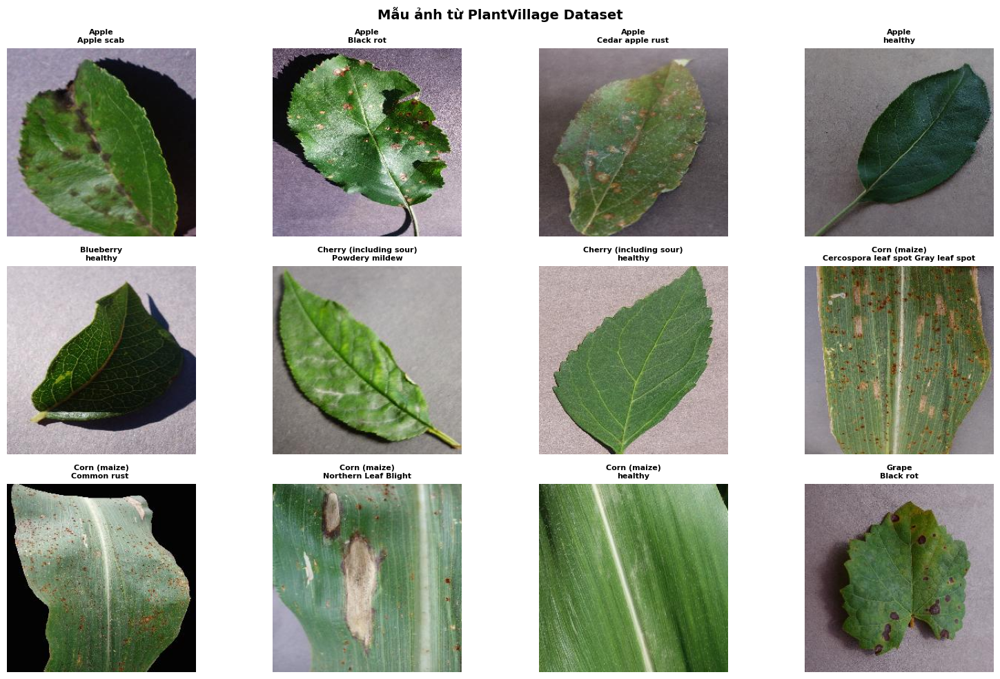

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

sample_classes = class_names[:12]
for i, cls in enumerate(sample_classes):
    cls_dir = os.path.join(DATASET_PATH, cls)
    imgs = [f for f in os.listdir(cls_dir) if os.path.splitext(f)[1].lower() in VALID_EXTS]
    if imgs:
        img_path = os.path.join(cls_dir, imgs[0])
        img = Image.open(img_path).convert('RGB')
        axes[i].imshow(img)
        short_name = cls.replace('___', '\n').replace('_', ' ')
        axes[i].set_title(short_name, fontsize=8, fontweight='bold')
        axes[i].axis('off')

plt.suptitle('Mẫu ảnh từ PlantVillage Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/03_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
data_records = []
for cls in class_names:
    cls_dir = os.path.join(DATASET_PATH, cls)
    imgs = [f for f in os.listdir(cls_dir) if os.path.splitext(f)[1].lower() in VALID_EXTS]
    plant = cls.split('___')[0]
    for img in imgs:
        data_records.append({
            'filepath': os.path.join(cls_dir, img),
            'disease_label': cls,
            'plant_label': plant
        })

df = pd.DataFrame(data_records)
print(f'📋 DataFrame tổng: {len(df):,} ảnh × {len(df.columns)} cột')

📋 DataFrame tổng: 22,698 ảnh × 3 cột


In [ ]:
le_disease = LabelEncoder()
df['disease_encoded'] = le_disease.fit_transform(df['disease_label'])

le_plant = LabelEncoder()
df['plant_encoded'] = le_plant.fit_transform(df['plant_label'])

print(f'✅ Mã hóa nhãn xong. Tổng lớp bệnh: {len(le_disease.classes_)} | Tổng loại cây: {len(le_plant.classes_)}')

✅ Mã hóa nhãn xong. Tổng lớp bệnh: 38 | Tổng loại cây: 14


In [ ]:
# ============================================================
# LƯU TRỮ LABELENCODER – Dùng lại ở bước Evaluation
# ============================================================
with open('/content/le_disease.pkl', 'wb') as f:
    pickle.dump(le_disease, f)
with open('/content/le_plant.pkl', 'wb') as f:
    pickle.dump(le_plant, f)

# Tự động đồng bộ hóa sang folder Drive (Sử dụng cấu hình chữ thường để tránh lỗi đường dẫn)
try:
    os.makedirs('/content/drive/MyDrive/Plantvillage dataset/metadata', exist_ok=True)
    shutil.copy('/content/le_disease.pkl', '/content/drive/MyDrive/Plantvillage dataset/metadata/le_disease.pkl')
    shutil.copy('/content/le_plant.pkl', '/content/drive/MyDrive/Plantvillage dataset/metadata/le_plant.pkl')
    print(' Đã lưu và đồng bộ LabelEncoder sang Google Drive thành công.')
except Exception as e:
    print(f' Cảnh báo lỗi đồng bộ Drive: {e}')

 Đã lưu và đồng bộ LabelEncoder sang Google Drive thành công.


In [ ]:
# Tách Test 15%
df_train_val, df_test = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df['disease_encoded']
)

#  Tách Validation từ phần còn lại
df_train, df_val = train_test_split(
    df_train_val,
    test_size=0.1765,
    random_state=42,
    stratify=df_train_val['disease_encoded']
)

# Lưu file phân chia CSV
df_train.to_csv('/content/split_train.csv', index=False)
df_val.to_csv('/content/split_val.csv', index=False)
df_test.to_csv('/content/split_test.csv', index=False)

print(' KẾT QUẢ CHIA DỮ LIỆU')
print(f'  Train (70%)   : {len(df_train):,} ảnh')
print(f'  Validation(15%): {len(df_val):,} ảnh')
print(f'  Test (15%)    : {len(df_test):,} ảnh')

 KẾT QUẢ CHIA DỮ LIỆU
  Train (70%)   : 15,887 ảnh
  Validation(15%): 3,406 ảnh
  Test (15%)    : 3,405 ảnh


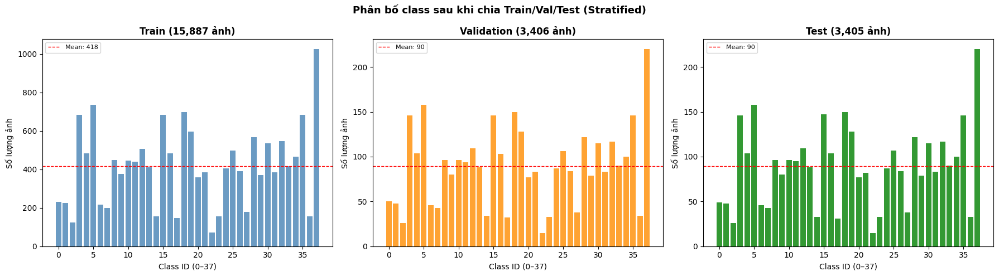

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
splits = [('Train', df_train), ('Validation', df_val), ('Test', df_test)]
colors_split = ['steelblue', 'darkorange', 'green']

for ax, (name, dfs), col in zip(axes, splits, colors_split):
    counts = dfs['disease_encoded'].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=col, alpha=0.8, width=0.8)
    ax.set_title(f'{name} ({len(dfs):,} ảnh)', fontweight='bold')
    ax.set_xlabel('Class ID (0–37)')
    ax.set_ylabel('Số lượng ảnh')
    ax.axhline(y=counts.mean(), color='red', linestyle='--', linewidth=1, label=f'Mean: {counts.mean():.0f}')
    ax.legend(fontsize=8)

plt.suptitle('Phân bố class sau khi chia Train/Val/Test (Stratified)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/04_split_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

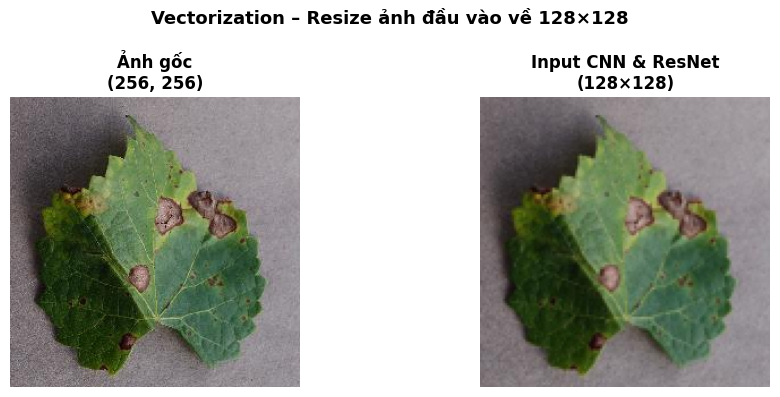

In [ ]:
sample_img_path = df_train.iloc[0]['filepath']
img_raw = Image.open(sample_img_path).convert('RGB')

# Resize toàn bộ ảnh về kích thước chuẩn 128×128 trước khi đưa vào model
img_input = img_raw.resize((IMG_SIZE, IMG_SIZE))
arr_cnn = np.array(img_input, dtype=np.float32)  # dùng lại ở cell sau

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_raw); axes[0].set_title(f'Ảnh gốc\n{img_raw.size}', fontweight='bold'); axes[0].axis('off')
axes[1].imshow(img_input); axes[1].set_title(f'Input CNN & ResNet\n({IMG_SIZE}×{IMG_SIZE})', fontweight='bold'); axes[1].axis('off')
plt.suptitle(f'Vectorization – Resize ảnh đầu vào về {IMG_SIZE}×{IMG_SIZE}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/05_vectorization_demo.png', dpi=150, bbox_inches='tight')
plt.show()

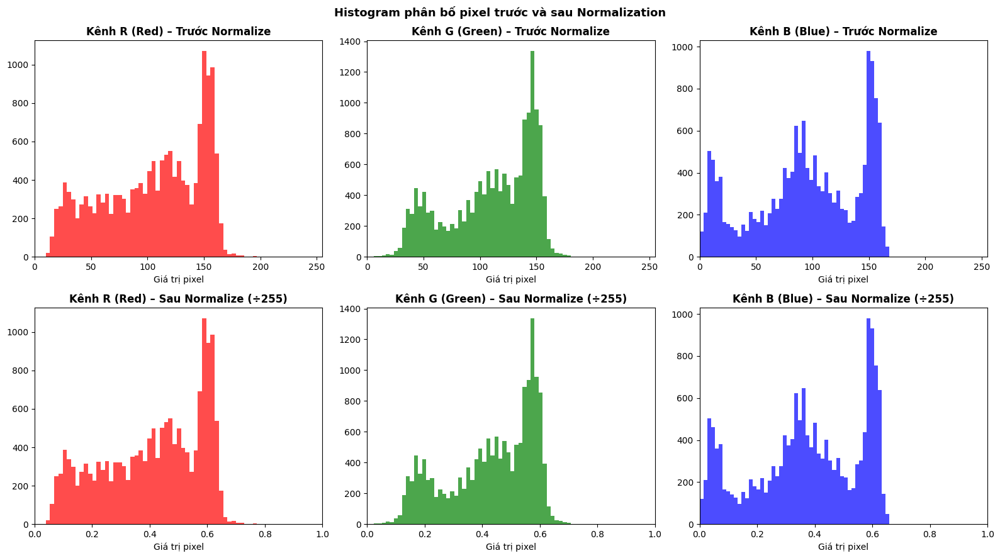

In [ ]:
# Tính ma trận ảnh chuẩn hóa trước khi vẽ biểu đồ histogram
arr_cnn_norm = arr_cnn / 255.0

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
channels_label = ['Kênh R (Red)', 'Kênh G (Green)', 'Kênh B (Blue)']
colors_ch = ['red', 'green', 'blue']

for i in range(3):
    axes[0][i].hist(arr_cnn[:,:,i].flatten(), bins=50, color=colors_ch[i], alpha=0.7, edgecolor='none')
    axes[0][i].set_title(f'{channels_label[i]} – Trước Normalize', fontweight='bold')
    axes[0][i].set_xlabel('Giá trị pixel')
    axes[0][i].set_xlim(0, 255)

    axes[1][i].hist(arr_cnn_norm[:,:,i].flatten(), bins=50, color=colors_ch[i], alpha=0.7, edgecolor='none')
    axes[1][i].set_title(f'{channels_label[i]} – Sau Normalize (÷255)', fontweight='bold')
    axes[1][i].set_xlabel('Giá trị pixel')
    axes[1][i].set_xlim(0, 1)

plt.suptitle('Histogram phân bố pixel trước và sau Normalization', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/06_normalization_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# TÍNH MEAN / STD PIXEL CỦA TẬP TRAIN (trên mẫu 500 ảnh)
# ============================================================
print('📊 THỐNG KÊ GIÁ TRỊ TRUNG BÌNH VÀ ĐỘ LỆCH CHUẨN (TRAIN SET)')
sample_train_paths = random.sample(list(df_train['filepath']), min(500, len(df_train)))
pixel_values = []

for path in sample_train_paths:
    try:
        arr = np.array(Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
        pixel_values.append(arr)
    except:
        pass

pixel_stack = np.stack(pixel_values, axis=0)
mean_r, mean_g, mean_b = pixel_stack[:,:,:,0].mean(), pixel_stack[:,:,:,1].mean(), pixel_stack[:,:,:,2].mean()
std_r, std_g, std_b = pixel_stack[:,:,:,0].std(), pixel_stack[:,:,:,1].std(), pixel_stack[:,:,:,2].std()

print(f'  Số mẫu ảnh tính toán: {len(pixel_values)}')
print(f'  Kênh Red   - Mean: {mean_r:.4f} | Std: {std_r:.4f}')
print(f'  Kênh Green - Mean: {mean_g:.4f} | Std: {std_g:.4f}')
print(f'  Kênh Blue  - Mean: {mean_b:.4f} | Std: {std_b:.4f}')

📊 THỐNG KÊ GIÁ TRỊ TRUNG BÌNH VÀ ĐỘ LỆCH CHUẨN (TRAIN SET)
  Số mẫu ảnh tính toán: 500
  Kênh Red   - Mean: 0.4670 | Std: 0.1906
  Kênh Green - Mean: 0.4892 | Std: 0.1684
  Kênh Blue  - Mean: 0.4126 | Std: 0.2072


In [ ]:
print(' TỔNG KẾT DATA PREPARATION – PlantVillage')
print('='*60)
print(f'    Tổng ảnh          : {total_images:,}')
print(f'    Tổng class (bệnh) : {len(class_names)} lớp')
print(f'    Số loại cây       : {df["plant_label"].nunique()}')
print(f'    Ảnh lỗi           : {len(errors)}')
print(f'    Kênh màu          : RGB (đã chuẩn hóa)')
print(f'    Đã phân chia dữ liệu Train/Val/Test có Stratified')
print(f'    Mean RGB (train): [{mean_r:.3f}, {mean_g:.3f}, {mean_b:.3f}]')
print(f'    Std  RGB (train): [{std_r:.3f}, {std_g:.3f}, {std_b:.3f}]')
print('\n ARTIFACTS METADATA ĐÃ XUẤT RA HỆ THỐNG:')
print('   - split_train.csv, split_val.csv, split_test.csv')
print('   - le_disease.pkl, le_plant.pkl (Lưu tại metadata folder trên Drive)')
print('   - class_weight_disease.json, class_weight_plant.json')

 TỔNG KẾT DATA PREPARATION – PlantVillage
    Tổng ảnh          : 22,698
    Tổng class (bệnh) : 38 lớp
    Số loại cây       : 14
    Ảnh lỗi           : 0
    Kênh màu          : RGB (đã chuẩn hóa)
    Đã phân chia dữ liệu Train/Val/Test có Stratified
    Mean RGB (train): [0.467, 0.489, 0.413]
    Std  RGB (train): [0.191, 0.168, 0.207]

 ARTIFACTS METADATA ĐÃ XUẤT RA HỆ THỐNG:
   - split_train.csv, split_val.csv, split_test.csv
   - le_disease.pkl, le_plant.pkl (Lưu tại metadata folder trên Drive)
   - class_weight_disease.json, class_weight_plant.json


# 🌿 PHẦN 2: MÔ HÌNH CNN – Phân loại bệnh cây (PlantVillage)
**Tiếp theo sau Data Preparation**  
Pipeline: Custom CNN 5 block | 38 lớp bệnh | Input 128×128 RGB

In [ ]:
# ============================================================
# IMPORT THÊM CHO PHẦN CNN
# ============================================================
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score
)

# ============================================================
# CẤU HÌNH CNN
# ============================================================
DRIVE_META  = '/content/drive/MyDrive/Plantvillage dataset/metadata'
DRIVE_MODEL = '/content/drive/MyDrive/Plantvillage dataset/models'
os.makedirs(DRIVE_MODEL, exist_ok=True)

IMG_SIZE    = IMG_SIZE_CNN   # 256
BATCH_SIZE  = 64
EPOCHS      = 50
LR          = 1e-3
NUM_CLASSES = 38

# Mean/Std từ cell 16 Data Preparation (dùng biến mean_r/g/b, std_r/g/b)
try:
    MEAN = np.array([mean_r, mean_g, mean_b], dtype=np.float32)
    STD  = np.array([std_r,  std_g,  std_b],  dtype=np.float32)
    print(f'✅ Dùng Mean/Std từ tập train: MEAN={MEAN}, STD={STD}')
except NameError:
    MEAN = np.array([0.469, 0.494, 0.414], dtype=np.float32)
    STD  = np.array([0.195, 0.170, 0.211], dtype=np.float32)
    print('⚠️ Dùng Mean/Std mặc định (chạy lại cell 16 nếu muốn chính xác hơn)')

tf.random.set_seed(42)

print(f'✅ TensorFlow: {tf.__version__}')
print(f'✅ GPU: {tf.config.list_physical_devices("GPU")}')
print(f'✅ Config: IMG={IMG_SIZE}, BATCH={BATCH_SIZE}, EPOCHS={EPOCHS}, LR={LR}')

✅ Dùng Mean/Std từ tập train: MEAN=[0.46704188 0.48917916 0.4125854 ], STD=[0.19063084 0.16841531 0.20717043]
✅ TensorFlow: 2.20.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Config: IMG=128, BATCH=64, EPOCHS=50, LR=0.001


## 🔄 Data Pipeline (tf.data)

In [ ]:
# ============================================================
# HÀM ĐỌC, RESIZE, CHUẨN HÓA ẢNH
# ============================================================
MEAN_TF = tf.constant(MEAN, dtype=tf.float32)
STD_TF  = tf.constant(STD,  dtype=tf.float32)

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    img = (img - MEAN_TF) / STD_TF   # normalize theo dataset
    return img, label

def augment_fn(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, 0.8, 1.2)
    img = tf.image.random_saturation(img, 0.8, 1.2)
    img = tf.image.random_hue(img, 0.05)
    return img, label

AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(df, augment=False, shuffle=False):
    # df_train / df_val / df_test đã có từ phần Data Preparation
    paths  = df['filepath'].values
    labels = df['disease_encoded'].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=42)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    if augment:
        ds = ds.map(augment_fn, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(df_train, augment=True,  shuffle=True)
val_ds   = make_dataset(df_val,   augment=False, shuffle=False)
test_ds  = make_dataset(df_test,  augment=False, shuffle=False)

print(f'✅ Train : {len(train_ds)} batch × {BATCH_SIZE} = ~{len(df_train):,} ảnh')
print(f'✅ Val   : {len(val_ds)} batch × {BATCH_SIZE} = ~{len(df_val):,} ảnh')
print(f'✅ Test  : {len(test_ds)} batch × {BATCH_SIZE} = ~{len(df_test):,} ảnh')

✅ Train : 249 batch × 64 = ~15,887 ảnh
✅ Val   : 54 batch × 64 = ~3,406 ảnh
✅ Test  : 54 batch × 64 = ~3,405 ảnh


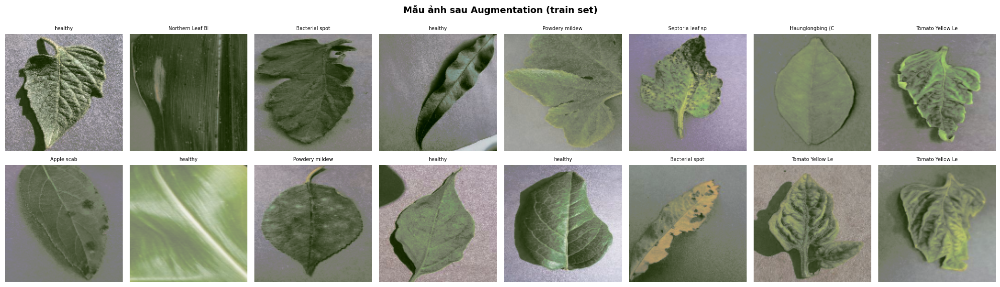

In [ ]:
# ============================================================
# VISUALIZE: XEM MẪU ẢNH SAU AUGMENTATION
# ============================================================
def denorm(img_tensor):
    """Đảo ngược normalize để hiển thị ảnh."""
    return np.clip(img_tensor.numpy() * STD + MEAN, 0, 1)

sample_imgs, sample_lbls = next(iter(train_ds))

fig, axes = plt.subplots(2, 8, figsize=(20, 6))
fig.suptitle('Mẫu ảnh sau Augmentation (train set)', fontsize=13, fontweight='bold')
for i, ax in enumerate(axes.flatten()):
    ax.imshow(denorm(sample_imgs[i]))
    cls_name = le_disease.inverse_transform([sample_lbls[i].numpy()])[0]
    ax.set_title(cls_name.split('___')[-1].replace('_',' ')[:16], fontsize=7)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 🏗️ Kiến trúc CNN

In [ ]:
# ============================================================
# XÂY DỰNG MÔ HÌNH CNN TÙY CHỈNH
# 5 Conv Blocks (32→64→128→256→512) + GAP + Dense Head
# ============================================================
def build_cnn(num_classes=38, input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    inp = keras.Input(shape=input_shape, name='input_image')

    # Block 1 – 32 filters → output 64×64
    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.20)(x)

    # Block 2 – 64 filters → output 32×32
    x = layers.Conv2D(64, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    # Block 3 – 128 filters → output 16×16
    x = layers.Conv2D(128, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.30)(x)

    # Block 4 – 256 filters → output 8×8
    x = layers.Conv2D(256, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(256, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.35)(x)

    # Block 5 – 512 filters → output 4×4
    x = layers.Conv2D(512, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(512, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.40)(x)

    # Classification Head
    x = layers.GlobalAveragePooling2D()(x)          # (512,)
    x = layers.Dense(512, use_bias=False,
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.50)(x)

    x = layers.Dense(256, use_bias=False,
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.40)(x)

    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    return keras.Model(inp, out, name='PlantDisease_CNN')


model = build_cnn(num_classes=NUM_CLASSES)
model.summary(line_length=80)
print(f'\n🔢 Tổng params: {model.count_params():,}')

Model: "PlantDisease_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)          │ (None, 128, 128, 3)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d (Conv2D)                   │ (None, 128, 128, 32)     │           864 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ batch_normalization               │ (None, 128, 128, 32)     │           128 │
│ (BatchNormalization)              │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ activation (Activation)           │ (None, 128, 128, 32)     │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 128, 128, 32)     │         9,216 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ batch_normalization_1             │ (None, 128, 128, 32)     │           128 │
│ (BatchNormalization)              │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ activation_1 (Activation)         │ (None, 128, 128, 32)     │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 64, 64, 32)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout (Dropout)                 │ (None, 64, 64, 32)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)                 │ (None, 64, 64, 64)       │        18,432 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ batch_normalization_2             │ (None, 64, 64, 64)       │           256 │
│ (BatchNormalization)              │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ activation_2 (Activation)         │ (None, 64, 64, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)                 │ (None, 64, 64, 64)       │        36,864 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ batch_normalization_3             │ (None, 64, 64, 64)       │           256 │
│ (BatchNormalization)              │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ activation_3 (Activation)         │ (None, 64, 64, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)    │ (None, 32, 32, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dropout_1 (Dropout)               │ (None, 32, 32, 64)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)                 │ (None, 32, 32, 128)      │        73,728 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ batch_normalization_4             │ (None, 32, 32, 128)      │           512 │
│ (BatchNormalization)              │                          │               │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ activation_4 (Activation)         │ (None, 32, 32, 128)      │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)                 │ (None, 32, 32, 128)      │       147,456 │
├──────────────────────────────

 Total params: 5,124,230 (19.55 MB)

 Trainable params: 5,118,726 (19.53 MB)

 Non-trainable params: 5,504 (21.50 KB)


🔢 Tổng params: 5,124,230


## ⚙️ Compile & Callbacks

In [ ]:
# ============================================================
# COMPILE
# ============================================================
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR),
    loss='sparse_categorical_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top3_acc'),
        keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc'),
    ]
)

# ============================================================
# CALLBACKS
# ============================================================
CKPT_PATH = os.path.join(DRIVE_MODEL, 'cnn_plantvillage_best.keras')

callbacks_list = [
    ModelCheckpoint(
        filepath=CKPT_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
]

# class_weight_disease dùng lại từ Data Preparation (cell 4)
print('✅ Model compiled.')
print(f'✅ Best checkpoint → {CKPT_PATH}')

✅ Model compiled.
✅ Best checkpoint → /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_best.keras


## 🚀 Huấn luyện

In [ ]:
# ============================================================
# TRAINING
# ============================================================
print('🚀 Bắt đầu huấn luyện CNN...')
print('='*60)

history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks_list,
    class_weight=class_weight_disease,   # từ Data Preparation (cell 4)
    verbose=1
)

print('\n✅ Huấn luyện hoàn tất!')

🚀 Bắt đầu huấn luyện CNN...
Epoch 1/50
249/249 ━━━━━━━━━━━━━━━━━━━━ 0s 22s/step - accuracy: 0.0838 - loss: 3.7044 - top3_acc: 0.2035 - top5_acc: 0.2959 
Epoch 1: val_accuracy improved from None to 0.18908, saving model to /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_best.keras
249/249 ━━━━━━━━━━━━━━━━━━━━ 6825s 27s/step - accuracy: 0.1384 - loss: 3.2918 - top3_acc: 0.3040 - top5_acc: 0.4212 - val_accuracy: 0.1891 - val_loss: 3.3375 - val_top3_acc: 0.3779 - val_top5_acc: 0.5138 - learning_rate: 0.0010
Epoch 2/50
248/249 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.2650 - loss: 2.5370 - top3_acc: 0.5275 - top5_acc: 0.6677
Epoch 2: val_accuracy improved from 0.18908 to 0.25837, saving model to /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Plantvillage dataset/m

## 📈 Kết quả huấn luyện

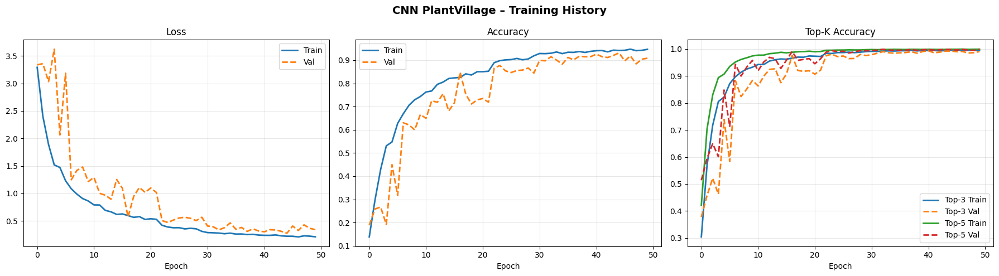

✅ Đã lưu biểu đồ training history.


In [ ]:
# ============================================================
# VẼ BIỂU ĐỒ TRAINING HISTORY
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('CNN PlantVillage – Training History', fontsize=14, fontweight='bold')

# Loss
axes[0].plot(history.history['loss'],     label='Train', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val',   linewidth=2, linestyle='--')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history.history['accuracy'],     label='Train', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Val',   linewidth=2, linestyle='--')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(alpha=0.3)

# Top-K Accuracy
axes[2].plot(history.history['top3_acc'],     label='Top-3 Train', linewidth=2)
axes[2].plot(history.history['val_top3_acc'], label='Top-3 Val',   linewidth=2, linestyle='--')
axes[2].plot(history.history['top5_acc'],     label='Top-5 Train', linewidth=2)
axes[2].plot(history.history['val_top5_acc'], label='Top-5 Val',   linewidth=2, linestyle='--')
axes[2].set_title('Top-K Accuracy'); axes[2].set_xlabel('Epoch')
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL, 'cnn_training_history.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ Đã lưu biểu đồ training history.')

## 🧪 Đánh giá trên Test Set

In [ ]:
# ============================================================
# LOAD BEST MODEL & ĐÁNH GIÁ
# ============================================================
best_model = keras.models.load_model(CKPT_PATH)
print(f'✅ Đã load best model từ: {CKPT_PATH}')

results = best_model.evaluate(test_ds, verbose=1)
print(f'\n  Test Loss    : {results[0]:.4f}')
print(f'  Test Accuracy: {results[1]*100:.2f}%')
print(f'  Top-3 Acc    : {results[2]*100:.2f}%')
print(f'  Top-5 Acc    : {results[3]*100:.2f}%')

✅ Đã load best model từ: /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_best.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 1198s 22s/step - accuracy: 0.9363 - loss: 0.2623 - top3_acc: 0.9924 - top5_acc: 0.9971

  Test Loss    : 0.2623
  Test Accuracy: 93.63%
  Top-3 Acc    : 99.24%
  Top-5 Acc    : 99.71%


In [ ]:
# ============================================================
# LẤY PREDICTIONS TOÀN BỘ TEST SET
# ============================================================
y_true, y_pred_proba = [], []

for imgs, labels in test_ds:
    preds = best_model.predict(imgs, verbose=0)
    y_pred_proba.append(preds)
    y_true.extend(labels.numpy())

y_pred_proba = np.concatenate(y_pred_proba, axis=0)
y_pred       = np.argmax(y_pred_proba, axis=1)
y_true       = np.array(y_true)

print(f'✅ Tổng mẫu test: {len(y_true):,}')
print(f'   Accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%')

✅ Tổng mẫu test: 3,405
   Accuracy: 93.63%


In [ ]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================
short_labels = [c.split('___')[-1].replace('_', ' ')[:25] for c in le_disease.classes_]

report = classification_report(y_true, y_pred, target_names=short_labels, digits=3)
print('📋 CLASSIFICATION REPORT:')
print(report)

with open(os.path.join(DRIVE_MODEL, 'cnn_classification_report.txt'), 'w', encoding='utf-8') as f:
    f.write(report)
print('✅ Đã lưu classification report.')

📋 CLASSIFICATION REPORT:
                           precision    recall  f1-score   support

               Apple scab      0.815     0.898     0.854        49
                Black rot      0.941     1.000     0.970        48
         Cedar apple rust      1.000     0.885     0.939        26
                  healthy      0.965     0.938     0.951       146
                  healthy      0.981     1.000     0.990       104
           Powdery mildew      0.980     0.943     0.961       158
                  healthy      0.979     1.000     0.989        46
Cercospora leaf spot Gray      0.879     0.674     0.763        43
             Common rust       1.000     0.979     0.989        96
     Northern Leaf Blight      0.835     0.887     0.861        80
                  healthy      1.000     1.000     1.000        96
                Black rot      0.920     0.842     0.879        95
     Esca (Black Measles)      0.893     0.991     0.939       109
Leaf blight (Isariopsis L      0.977

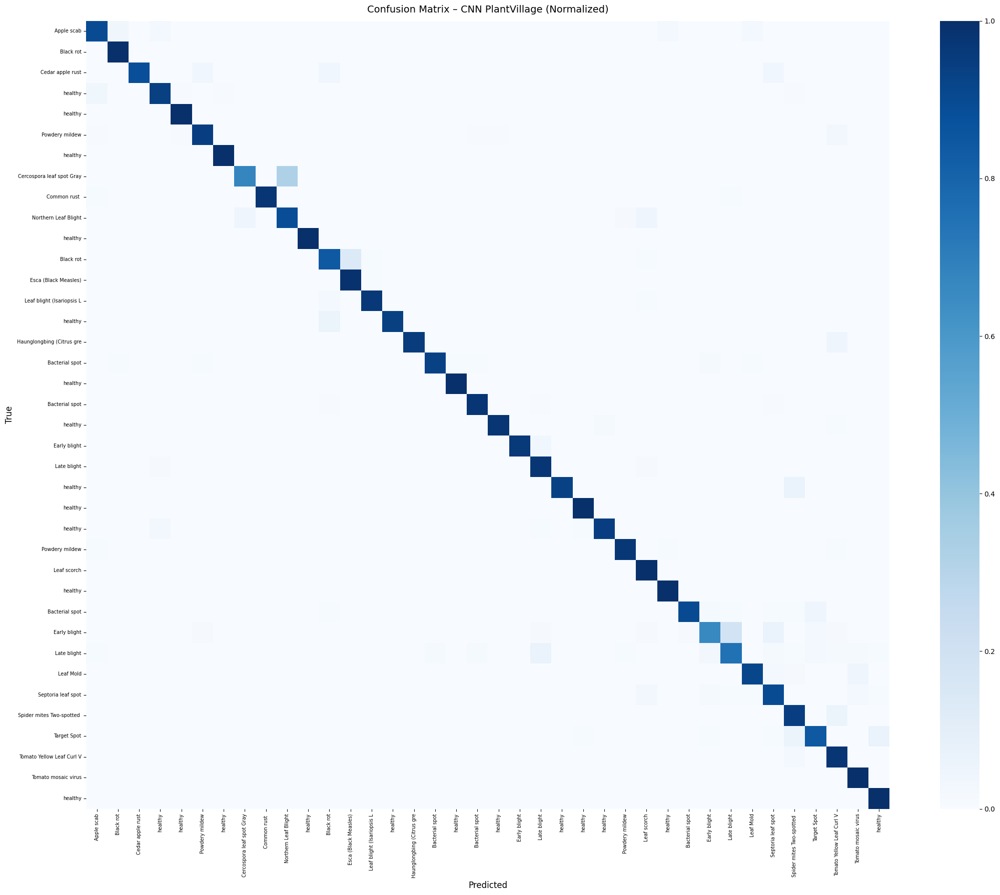

✅ Đã lưu confusion matrix.


In [ ]:
# ============================================================
# CONFUSION MATRIX
# ============================================================
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(cm_norm, annot=False, cmap='Blues', ax=ax,
            xticklabels=short_labels, yticklabels=short_labels)
ax.set_title('Confusion Matrix – CNN PlantVillage (Normalized)', fontsize=14, pad=12)
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True',      fontsize=12)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0,  fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL, 'cnn_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ Đã lưu confusion matrix.')

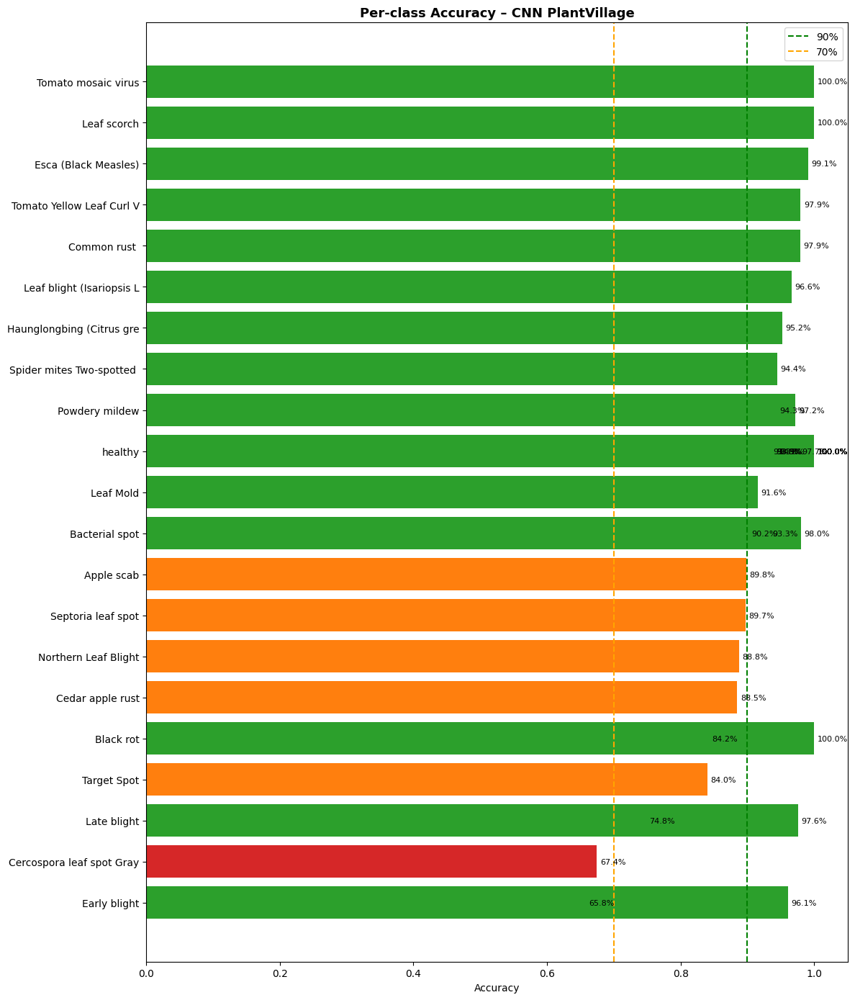

In [ ]:
# ============================================================
# PER-CLASS ACCURACY BAR CHART
# ============================================================
per_class_acc = cm_norm.diagonal()
sorted_idx    = np.argsort(per_class_acc)

colors_bar = ['#d62728' if v < 0.70 else '#ff7f0e' if v < 0.90 else '#2ca02c'
              for v in per_class_acc[sorted_idx]]

fig, ax = plt.subplots(figsize=(12, 14))
bars = ax.barh([short_labels[i] for i in sorted_idx], per_class_acc[sorted_idx], color=colors_bar)
ax.axvline(0.90, color='green',  linestyle='--', linewidth=1.5, label='90%')
ax.axvline(0.70, color='orange', linestyle='--', linewidth=1.5, label='70%')
ax.set_xlabel('Accuracy'); ax.set_xlim(0, 1.05)
ax.set_title('Per-class Accuracy – CNN PlantVillage', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
for bar, val in zip(bars, per_class_acc[sorted_idx]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.1%}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL, 'cnn_per_class_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()

## 🔍 Grad-CAM – Visualize vùng model chú ý

✅ Last conv layer: conv2d_9


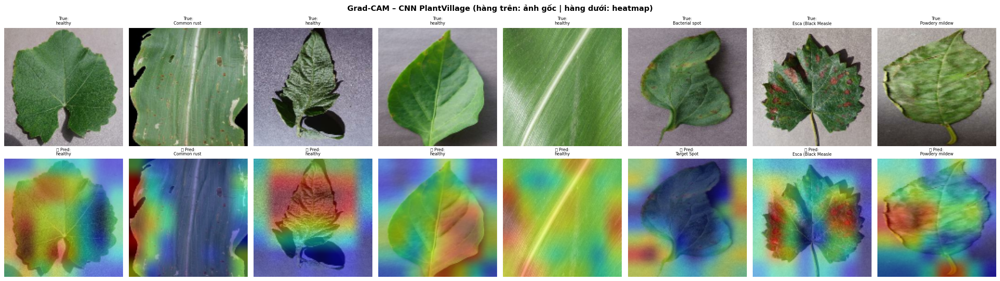

✅ Đã lưu Grad-CAM.


In [ ]:
# ============================================================
# GRAD-CAM
# ============================================================
def make_gradcam_heatmap(img_array, model, last_conv_name, pred_index=None):
    grad_model = keras.Model(
        inputs=model.input,
        outputs=[model.get_layer(last_conv_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads    = tape.gradient(class_channel, conv_outputs)
    pooled   = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap  = conv_outputs[0] @ pooled[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(orig_np, heatmap, alpha=0.45):
    hm_color = plt.cm.jet(np.uint8(255 * heatmap))[:, :, :3]
    hm_color = np.array(Image.fromarray(np.uint8(hm_color * 255)).resize(
        (orig_np.shape[1], orig_np.shape[0]))) / 255.0
    return np.clip(hm_color * alpha + np.clip(orig_np, 0, 1) * (1 - alpha), 0, 1)

# Tìm tên conv layer cuối cùng
last_conv = [l.name for l in best_model.layers if 'conv' in l.name][-1]
print(f'✅ Last conv layer: {last_conv}')

sample_imgs, sample_lbls = next(iter(test_ds))
n_show = 8

fig, axes = plt.subplots(2, n_show, figsize=(24, 7))
fig.suptitle('Grad-CAM – CNN PlantVillage (hàng trên: ảnh gốc | hàng dưới: heatmap)', fontsize=13, fontweight='bold')

for i in range(n_show):
    img_t   = tf.expand_dims(sample_imgs[i], 0)
    heatmap = make_gradcam_heatmap(img_t, best_model, last_conv)
    orig_np = denorm(sample_imgs[i])
    overlay = overlay_gradcam(orig_np, heatmap)

    pred_idx  = np.argmax(best_model.predict(img_t, verbose=0))
    true_name = short_labels[sample_lbls[i].numpy()]
    pred_name = short_labels[pred_idx]
    match     = '✅' if pred_idx == sample_lbls[i].numpy() else '❌'

    axes[0, i].imshow(orig_np);  axes[0, i].axis('off')
    axes[0, i].set_title(f'True:\n{true_name[:18]}', fontsize=7)
    axes[1, i].imshow(overlay);  axes[1, i].axis('off')
    axes[1, i].set_title(f'{match} Pred:\n{pred_name[:18]}', fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL, 'cnn_gradcam.png'), dpi=150, bbox_inches='tight')
plt.show()
print('✅ Đã lưu Grad-CAM.')

## 💾 Lưu Model & Tổng kết

In [ ]:
# ============================================================
# LƯU MODEL & HISTORY
# ============================================================
final_path = os.path.join(DRIVE_MODEL, 'cnn_plantvillage_final.keras')
best_model.save(final_path)
print(f'✅ Model cuối → {final_path}')

with open(os.path.join(DRIVE_MODEL, 'cnn_history.json'), 'w') as f:
    json.dump({k: [float(v) for v in vals]
               for k, vals in history.history.items()}, f, indent=2)
print('✅ History đã lưu.')

# ============================================================
# TỔNG KẾT
# ============================================================
best_val_acc = max(history.history['val_accuracy'])
best_epoch   = np.argmax(history.history['val_accuracy']) + 1

print('\n' + '='*60)
print('🎯 TỔNG KẾT CNN – PlantVillage')
print('='*60)
print(f'   Kiến trúc     : Custom CNN (5 Conv Blocks)')
print(f'   Tổng params   : {best_model.count_params():,}')
print(f'   Input size    : {IMG_SIZE}×{IMG_SIZE}×3')
print(f'   Epochs chạy   : {len(history.history["loss"])} / {EPOCHS}')
print(f'   Best epoch    : {best_epoch}')
print(f'   Best Val Acc  : {best_val_acc*100:.2f}%')
print(f'   Test Loss     : {results[0]:.4f}')
print(f'   Test Accuracy : {results[1]*100:.2f}%')
print(f'   Top-3 Acc     : {results[2]*100:.2f}%')
print(f'   Top-5 Acc     : {results[3]*100:.2f}%')
print('='*60)
print('\n📁 Files đã lưu tại Drive/models/:')
for fname in [
    'cnn_plantvillage_best.keras',
    'cnn_plantvillage_final.keras',
    'cnn_training_history.png',
    'cnn_confusion_matrix.png',
    'cnn_per_class_accuracy.png',
    'cnn_gradcam.png',
    'cnn_classification_report.txt',
    'cnn_history.json',
]:
    print(f'   ✅ {fname}')

✅ Model cuối → /content/drive/MyDrive/Plantvillage dataset/models/cnn_plantvillage_final.keras
✅ History đã lưu.

🎯 TỔNG KẾT CNN – PlantVillage
   Kiến trúc     : Custom CNN (5 Conv Blocks)
   Tổng params   : 5,124,230
   Input size    : 128×128×3
   Epochs chạy   : 50 / 50
   Best epoch    : 45
   Best Val Acc  : 93.13%
   Test Loss     : 0.2623
   Test Accuracy : 93.63%
   Top-3 Acc     : 99.24%
   Top-5 Acc     : 99.71%

📁 Files đã lưu tại Drive/models/:
   ✅ cnn_plantvillage_best.keras
   ✅ cnn_plantvillage_final.keras
   ✅ cnn_training_history.png
   ✅ cnn_confusion_matrix.png
   ✅ cnn_per_class_accuracy.png
   ✅ cnn_gradcam.png
   ✅ cnn_classification_report.txt
   ✅ cnn_history.json
